  Patient_ID Patient_Name   Age  Gender Blood_Group        City  \
0     P10001    Patient_1  52.0    Male         AB-  Coimbatore   
1     P10002    Patient_2  26.0    Male          O-   Hyderabad   
2     P10003    Patient_3  26.0  Female         AB+  Coimbatore   
3     P10004    Patient_4  26.0  Female          O+     Chennai   
4     P10005    Patient_5  46.0    Male         AB-     Madurai   

  Admission_Date Discharge_Date        Department   Diagnosis      Doctor  \
0     10-05-2025     23-05-2025  General Medicine    Diabetes     Dr. Raj   
1     10-11-2025     16-11-2025       Dermatology   Psoriasis     Dr. Raj   
2     02-05-2023     13-05-2023  General Medicine    Diabetes  Dr. Suresh   
3     11-04-2024     16-04-2024               ENT   Sinusitis  Dr. Anitha   
4     27-11-2023     10-12-2023        Cardiology  Arrhythmia   Dr. Meena   

      Treatment     Room_Type  Stay_Days  Total_Bill Insurance Payment_Mode  \
0  Radiotherapy       General         13     98067.0   

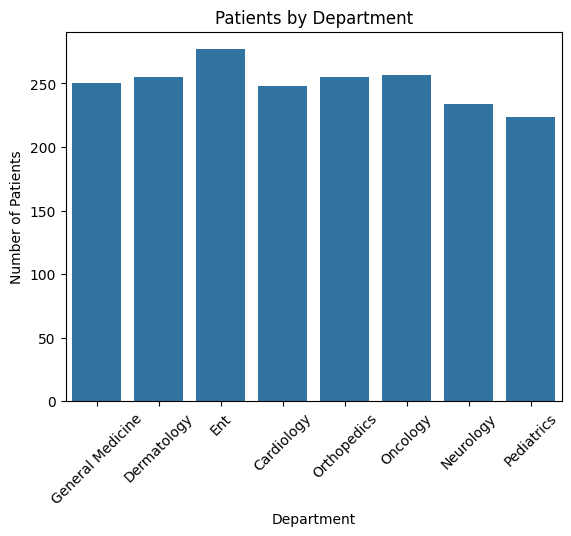

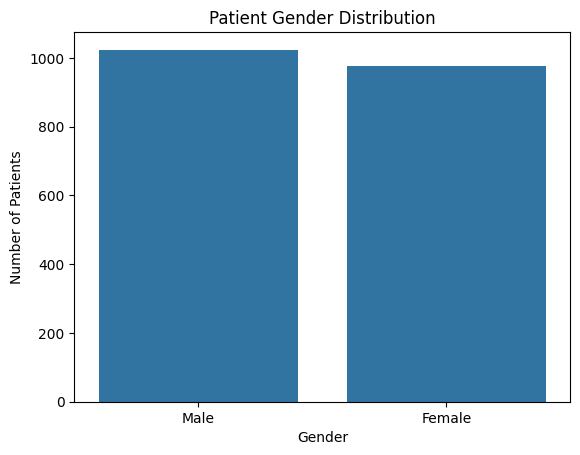

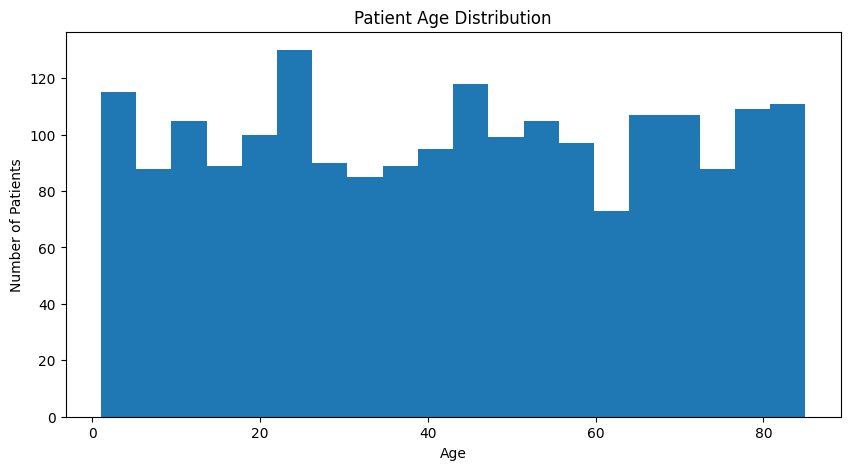

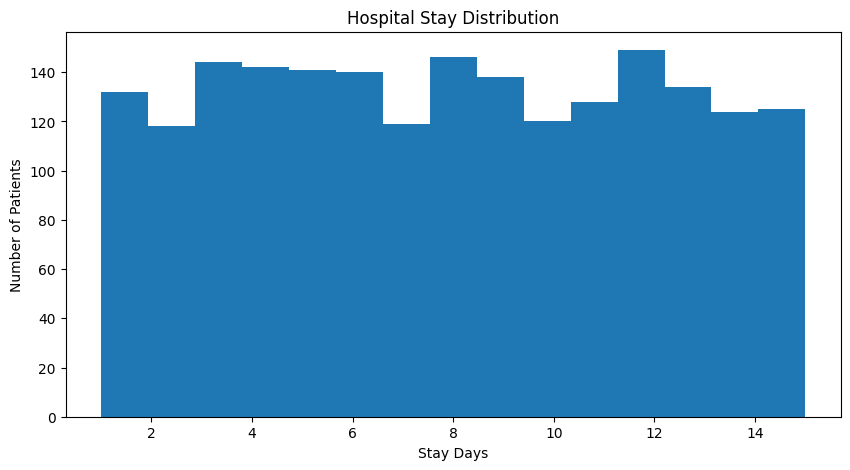

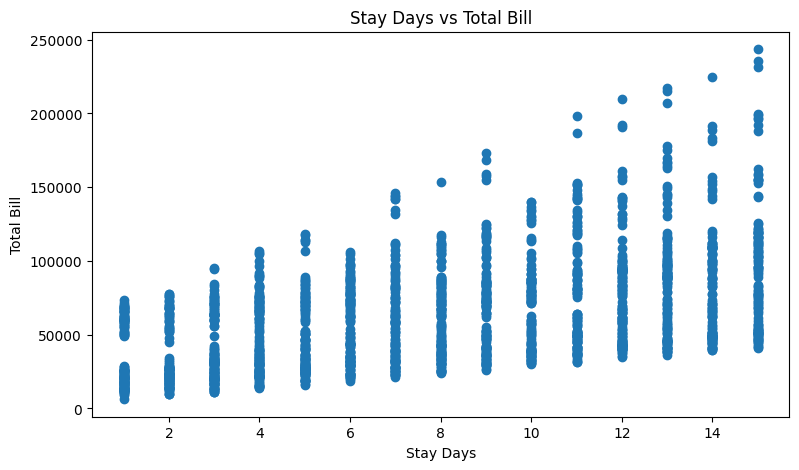

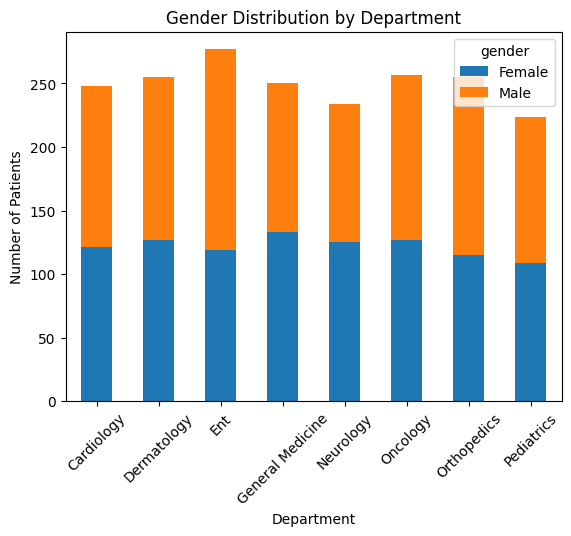

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# from google.colab import files

# uploaded = files.upload()

df = pd.read_csv("healthcare_hospital_raw_2000.csv (1).csv")

print(df.head())

# Dataset details
print(df.shape)
print(df.columns)
df.info()
print(df.describe())
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Clean text data
df["gender"] = df["gender"].str.title()
df["city"] = df["city"].str.title()
df["department"] = df["department"].str.title()
df["diagnosis"] = df["diagnosis"].str.title()

# Convert age into numeric
df["age"] = pd.to_numeric(df["age"], errors="coerce")

df.loc[(df["age"] < 0) | (df["age"] > 100), "age"] = np.nan

df["age"] = df["age"].fillna(df["age"].median())

# Clean stay days
df["stay_days"] = pd.to_numeric(df["stay_days"], errors="coerce")

df.loc[df["stay_days"] <= 0, "stay_days"] = np.nan

df["stay_days"] = df["stay_days"].fillna(df["stay_days"].median())

# Clean total bill
df["total_bill"] = pd.to_numeric(df["total_bill"], errors="coerce")

df.loc[df["total_bill"] < 0, "total_bill"] = np.nan

df["total_bill"] = df["total_bill"].fillna(df["total_bill"].median())

# Clean patient satisfaction
df["patient_satisfaction"] = pd.to_numeric(
    df["patient_satisfaction"], errors="coerce"
)

df.loc[
    (df["patient_satisfaction"] < 1) |
    (df["patient_satisfaction"] > 5),
    "patient_satisfaction"
] = np.nan

df["patient_satisfaction"] = df["patient_satisfaction"].fillna(
    df["patient_satisfaction"].median()
)

# Convert dates
df["admission_date"] = pd.to_datetime(
    df["admission_date"], errors="coerce", dayfirst=True
)

df["discharge_date"] = pd.to_datetime(
    df["discharge_date"], errors="coerce", dayfirst=True
)

# Check discharge date
df.loc[
    df["discharge_date"] < df["admission_date"],
    "discharge_date"
] = pd.NaT

# Calculate hospital stay
df["calculated_stay_days"] = (
    df["discharge_date"] - df["admission_date"]
).dt.days

# Check cleaned data
print("Duplicates:", df.duplicated().sum())
print("Missing values:")
print(df.isnull().sum())

print(df.head())


# ANALYSIS

# Total patients
print("Total Patients:", df["patient_id"].nunique())

# Total revenue
print("Total Revenue:", df["total_bill"].sum())

# Average bill
print("Average Bill:", round(df["total_bill"].mean(), 2))

# Average age
print("Average Age:", round(df["age"].mean(), 2))

# Average stay
print("Average Stay:", round(df["stay_days"].mean(), 2))

# Average satisfaction
print("Average Satisfaction:",
      round(df["patient_satisfaction"].mean(), 2))


# Department analysis
department_analysis = df.groupby("department").agg(
    Total_Patients=("patient_id", "count"),
    Total_Revenue=("total_bill", "sum"),
    Average_Bill=("total_bill", "mean"),
    Average_Stay=("stay_days", "mean"),
    Average_Satisfaction=("patient_satisfaction", "mean")
)

print(department_analysis.round(2))


# Department-wise patients
sns.countplot(data=df, x="department")

plt.title("Patients by Department")
plt.xlabel("Department")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()


# Gender distribution
sns.countplot(data=df, x="gender")

plt.title("Patient Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.show()


# Age distribution
plt.figure(figsize=(10, 5))

plt.hist(df["age"], bins=20)

plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()


# Hospital stay distribution
plt.figure(figsize=(10, 5))

plt.hist(df["stay_days"], bins=15)

plt.title("Hospital Stay Distribution")
plt.xlabel("Stay Days")
plt.ylabel("Number of Patients")
plt.show()


# Stay days vs total bill
plt.figure(figsize=(9, 5))

plt.scatter(df["stay_days"], df["total_bill"])

plt.title("Stay Days vs Total Bill")
plt.xlabel("Stay Days")
plt.ylabel("Total Bill")
plt.show()


# Department-wise gender
gender_department = pd.crosstab(
    df["department"], df["gender"]
)

gender_department.plot(kind="bar", stacked=True)

plt.title("Gender Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()


# Save cleaned dataset
df.to_csv("healthcare_hospital_cleaned.csv", index=False)

# Download file
files.download("healthcare_hospital_cleaned.csv")
